In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

results_path = output_dir / "day50_automated_quality_results.csv"
results_df = pd.read_csv(results_path)

print("Dataset shape:", results_df.shape)
print("\nMethods:", results_df["method"].unique())
print("\nInactive sensor counts:", sorted(results_df["inactive_sensors"].unique()))
print("\nMissing values:")
print(results_df.isnull().sum())


Dataset shape: (15, 6)

Methods: <StringArray>
['Incomplete', 'Linear', 'Cubic Spline']
Length: 3, dtype: str

Inactive sensor counts: [np.int64(0), np.int64(4), np.int64(8), np.int64(12), np.int64(16)]

Missing values:
inactive_sensors       0
inactive_percentage    0
method                 0
SNR_dB                 0
PSNR_dB                0
SSIM                   0
dtype: int64


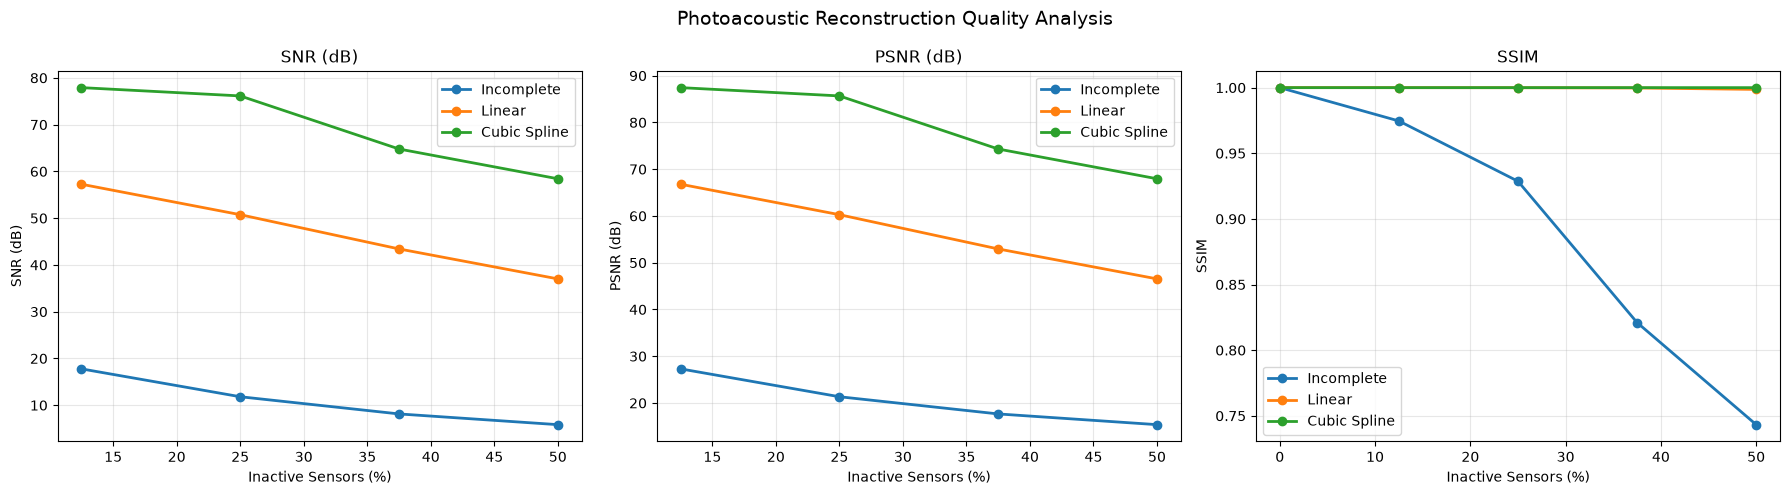

In [2]:

metrics = [
    ("SNR_dB", "SNR (dB)"),
    ("PSNR_dB", "PSNR (dB)"),
    ("SSIM", "SSIM")
]

methods = ["Incomplete", "Linear", "Cubic Spline"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (metric, title) in zip(axes, metrics):
    for method in methods:
        subset = results_df[results_df["method"] == method]
        summary = subset.groupby("inactive_percentage")[metric].mean()

        ax.plot(
            summary.index,
            summary.values,
            marker="o",
            linewidth=2,
            label=method
        )

    ax.set_title(title)
    ax.set_xlabel("Inactive Sensors (%)")
    ax.set_ylabel(title)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle("Photoacoustic Reconstruction Quality Analysis", fontsize=14)
plt.tight_layout()

plt.savefig(
    str(output_dir / "day53_combined_quality_analysis.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
